# Education Project: Socioeconomic Factors Associated with ACT Scores | Exploratory Data Analysis

This notebook explores the distribution of average ACT scores and their relationships with socioeconomic and various school characteristics. We examine descriptive statistics, numerical distributions, differences across states and school categories, and correlations between socioeconomic predictors and ACT scores. The findings will help us identify predictors and model for the subsequent regression analysis.

## Import Libraries and Dataset

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [2]:
from pathlib import Path

DATA_DIR = Path('../data')

final_dataset_path = DATA_DIR / 'education_final.csv'

df = pd.read_csv(final_dataset_path  , dtype = {'id': object, 'zip_code': object})

In [3]:
# Inspect first few rows of the final dataframe
df.head(5)

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,grade_12_offered
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,Yes
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,Yes
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,Yes
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,Yes


In [4]:
# Inspect dataframe. Make note or data type and number of non-null rows.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7857 non-null   object 
 1   rate_unemployment  7857 non-null   float64
 2   percent_college    7857 non-null   float64
 3   percent_married    7857 non-null   float64
 4   median_income      7857 non-null   float64
 5   average_act        7857 non-null   float64
 6   percent_lunch      7857 non-null   float64
 7   year               7857 non-null   str    
 8   state              7857 non-null   str    
 9   zip_code           7857 non-null   object 
 10  school_type        7857 non-null   str    
 11  school_level       7857 non-null   str    
 12  charter            7857 non-null   str    
 13  grade_12_offered   7857 non-null   str    
dtypes: float64(6), object(2), str(6)
memory usage: 1.1+ MB


In [5]:
# Review summary statistics
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7857.000000,7857.000000,7857.000000,7857.000000,7857.000000,7857.000000
mean,0.097815,0.569612,0.636201,52201.348229,20.237678,0.417964
std,0.057848,0.165714,0.194294,24153.361067,2.519787,0.236499
min,0.000000,0.091493,0.000000,821.792472,12.362637,0.000000
25%,0.058497,0.451524,0.527306,36816.000000,18.700000,0.238500
50%,0.085169,0.555747,0.668904,47026.000000,20.421245,0.378956
75%,0.122268,0.677113,0.777778,61558.000000,21.959707,0.568707
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


In [6]:
# Create a list of all predictors
predictors = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'school_level',
    'charter'
]

In [7]:
# Seperate numerical predictors into its own list
numerical_predictors = df[predictors].select_dtypes(include = 'number').columns.to_list()

In [8]:
numerical_predictors

['rate_unemployment',
 'percent_college',
 'percent_married',
 'median_income',
 'percent_lunch']

* We have imported our final dataset.
* We are working with 7857 rows.
* No null values in any rows/columns.
* Datatype seems to be correct for all columns.
* Summary statistics show that data is within correct bounds.

## Explore Average ACT Score

Create a histogram plot of average ACT score to review distribution

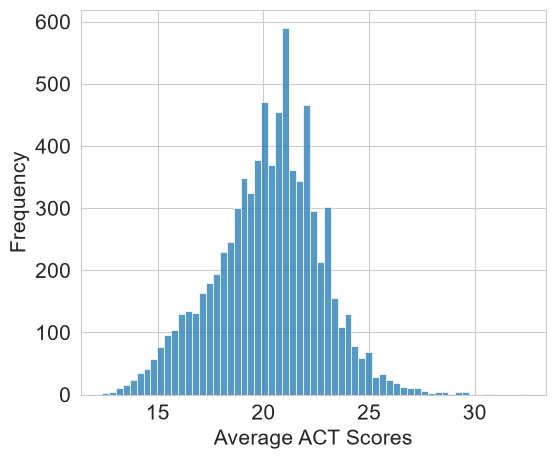

In [9]:
plt.figure(figsize=(6,5))

sns.histplot(data=df, x='average_act')

plt.xlabel('Average ACT Scores',fontsize=15)
plt.ylabel('Frequency', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

* The distribution of average ACT or ACT-equivalent scores is nearly bell-shaped and unimodal
* Most schools' average act score is concentrated around 20–22.
* There are some schools with extreme high and low scores.

Create a boxplot to visualize median, quantile range and outliers

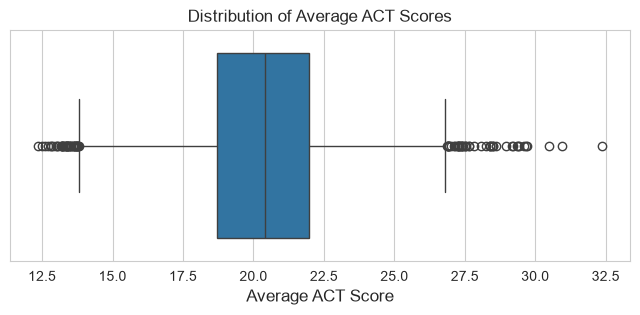

In [10]:
plt.figure(figsize=(8, 3))

sns.boxplot(data=df, x='average_act')

plt.title('Distribution of Average ACT Scores')
plt.xlabel('Average ACT Score', fontsize=12)
plt.yticks([])

plt.show()

In [11]:
df['average_act'].describe()

count    7857.000000
mean       20.237678
std         2.519787
min        12.362637
25%        18.700000
50%        20.421245
75%        21.959707
max        32.362637
Name: average_act, dtype: float64

* Middle 50% of ACT score are between 18.7 and 21.96
* Standard deviation is 2.52
* Median average ACT score is 20.42 with mean score 20.24
* There are outliers on both ends of the boxplot

## Explore Socioeconomic predictors

Histogram to see distribution of Median Household Income

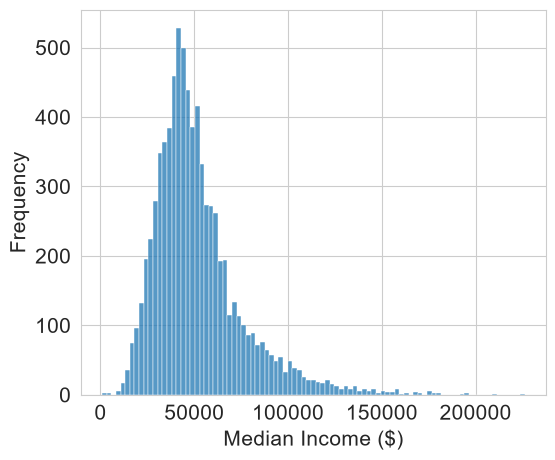

In [12]:
plt.figure(figsize=(6,5))

sns.histplot(data=df, x='median_income')

plt.xlabel('Median Income ($)',fontsize=15)
plt.ylabel('Frequency', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

* Histogram shows a unimodal distribution with median income skewed right.
* Most observations centered around $50,000

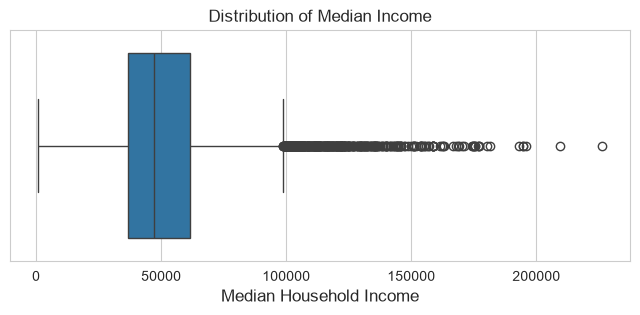

In [13]:
plt.figure(figsize=(8, 3))

sns.boxplot(data=df, x='median_income')

plt.title('Distribution of Median Income')
plt.xlabel('Median Household Income', fontsize=12)
plt.yticks([])

plt.show()

In [14]:
df['median_income'].describe()

count      7857.000000
mean      52201.348229
std       24153.361067
min         821.792472
25%       36816.000000
50%       47026.000000
75%       61558.000000
max      226181.000000
Name: median_income, dtype: float64

* Median income is **\$47,026**, with mean income of **\$52,201**.
* The boxplot identifies numerous potential outliers on the upper end of the distribution.

Explore Unemployment Rate

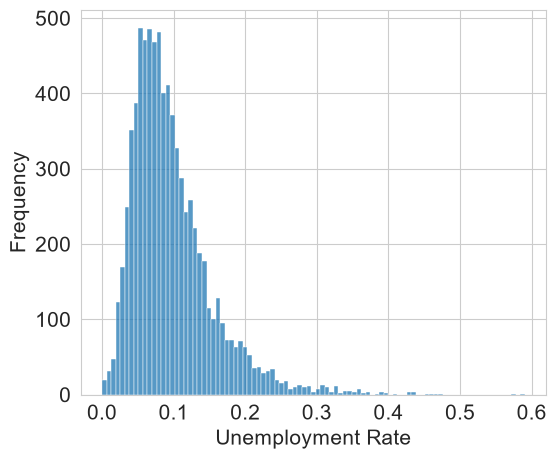

In [15]:
plt.figure(figsize=(6,5))

sns.histplot(data=df, x='rate_unemployment')

plt.xlabel('Unemployment Rate',fontsize=15)
plt.ylabel('Frequency', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

* The distribution is unimodal, right skewed with outliers on the top end.
* The distribution is centered around .08.

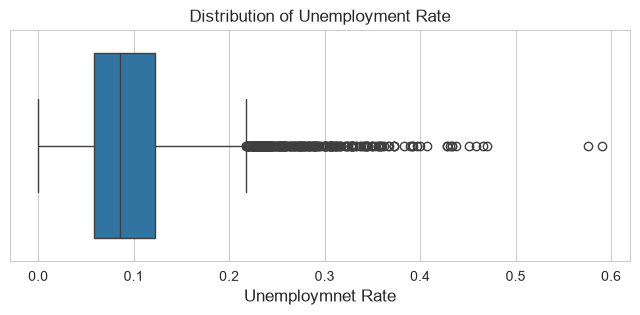

In [16]:
plt.figure(figsize=(8, 3))

sns.boxplot(data=df, x='rate_unemployment')

plt.title('Distribution of Unemployment Rate')
plt.xlabel('Unemploymnet Rate', fontsize=12)
plt.yticks([])

plt.show()

In [17]:
df['rate_unemployment'].describe()

count    7857.000000
mean        0.097815
std         0.057848
min         0.000000
25%         0.058497
50%         0.085169
75%         0.122268
max         0.590278
Name: rate_unemployment, dtype: float64

* Outliers on the upper end of the distribution.
* Median unemployment rate is .085 and mean unemployment is .098.
* Standard deviation is .058 (5.8%) which indicates considerable variation in unemployment rates.

## Review Potential Categorical Predictors

Average ACT Score by State 

In [18]:
state_act = (
    df.groupby('state')['average_act']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
)

state_act

,count,mean,median,std
state,,,,
WI,385,21.910909,22.300000,2.135558
MA,285,21.804961,22.081807,2.738336
WA,273,21.392322,21.495726,2.191391
OH,693,21.067821,21.000000,2.245037
NJ,350,20.801988,21.251526,3.180080
MO,349,20.761891,20.900000,1.974291
PA,595,20.654570,21.031746,2.465222
IN,347,20.641638,20.677656,1.569005
NC,414,20.404022,20.531136,2.185154


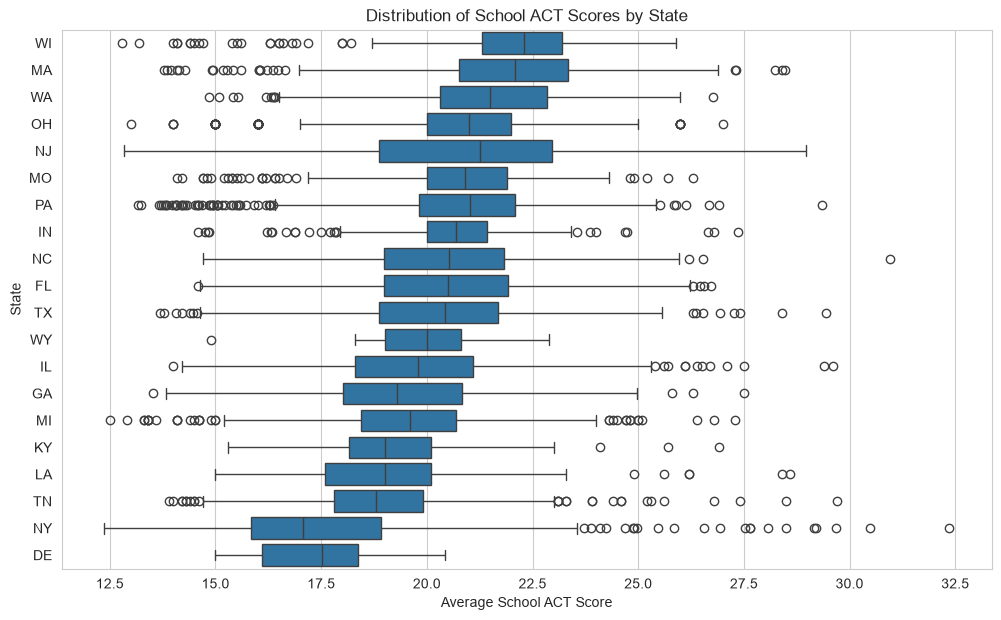

In [19]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='average_act',
    y='state',
    order=state_act.index
)

plt.title('Distribution of School ACT Scores by State')
plt.xlabel('Average School ACT Score')
plt.ylabel('State')

plt.show()

* Wisconsin, MA, WA show higher median Act scores
* New York, Delaware and TN on the lower end
* New Jersey has a big spread and no outliers.
* Wisconsin has numerous outliers on the lower end as oppposed to opposite is true for NY.

Additional review of School Level and Charter status

In [20]:
school_level_act = (
    df.groupby('school_level')['average_act']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
)

school_level_act

,count,mean,median,std
school_level,,,,
High,7227,20.298577,20.5,2.508415
Other,630,19.539078,19.6,2.546552


* Standard Deviation is consistent for both categories
* Small difference in Mean

In [21]:
charter_act = (
    df.groupby('charter')['average_act']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
)

charter_act

,count,mean,median,std
charter,,,,
No,7296,20.321043,20.543346,2.501445
Not applicable,216,19.193519,19.000000,1.674808
Yes,345,19.128409,19.175824,2.913517


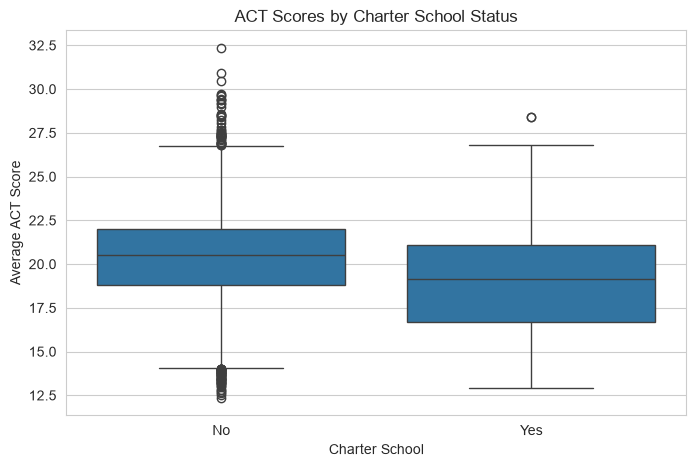

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[df['charter'].isin(['Yes', 'No'])],
    x='charter',
    y='average_act',
    order=['No', 'Yes']
)

plt.title('ACT Scores by Charter School Status')
plt.xlabel('Charter School')
plt.ylabel('Average ACT Score')

plt.show()

* Non-charter schools have average ACT scores higher than charter schools.
* Charter schools show somewhat higher variability. Standard deviation of 2.91 compared with 2.50 for Non Chartar Schools.

## Pair plots to see relation

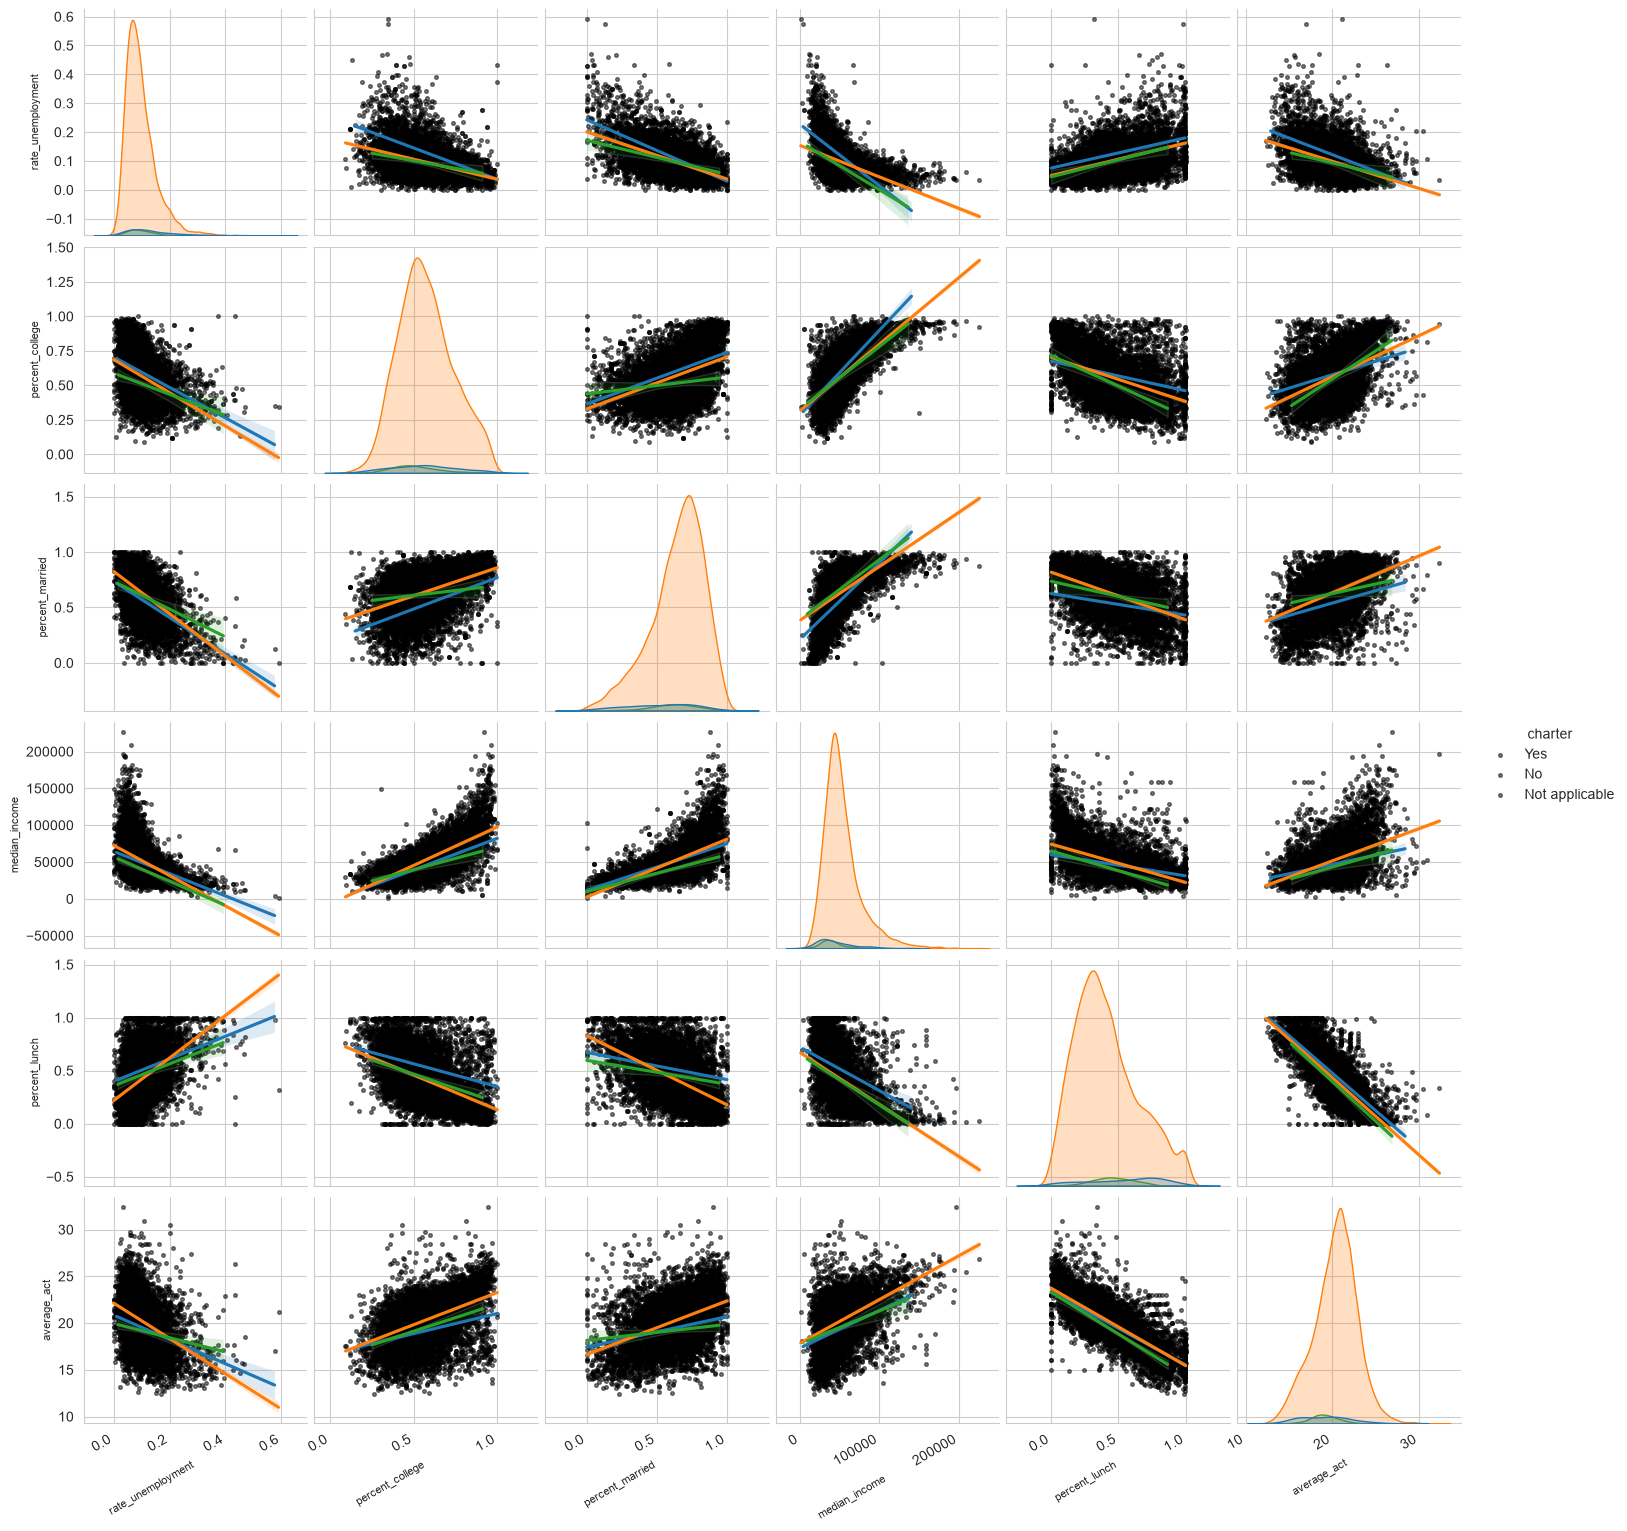

In [23]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

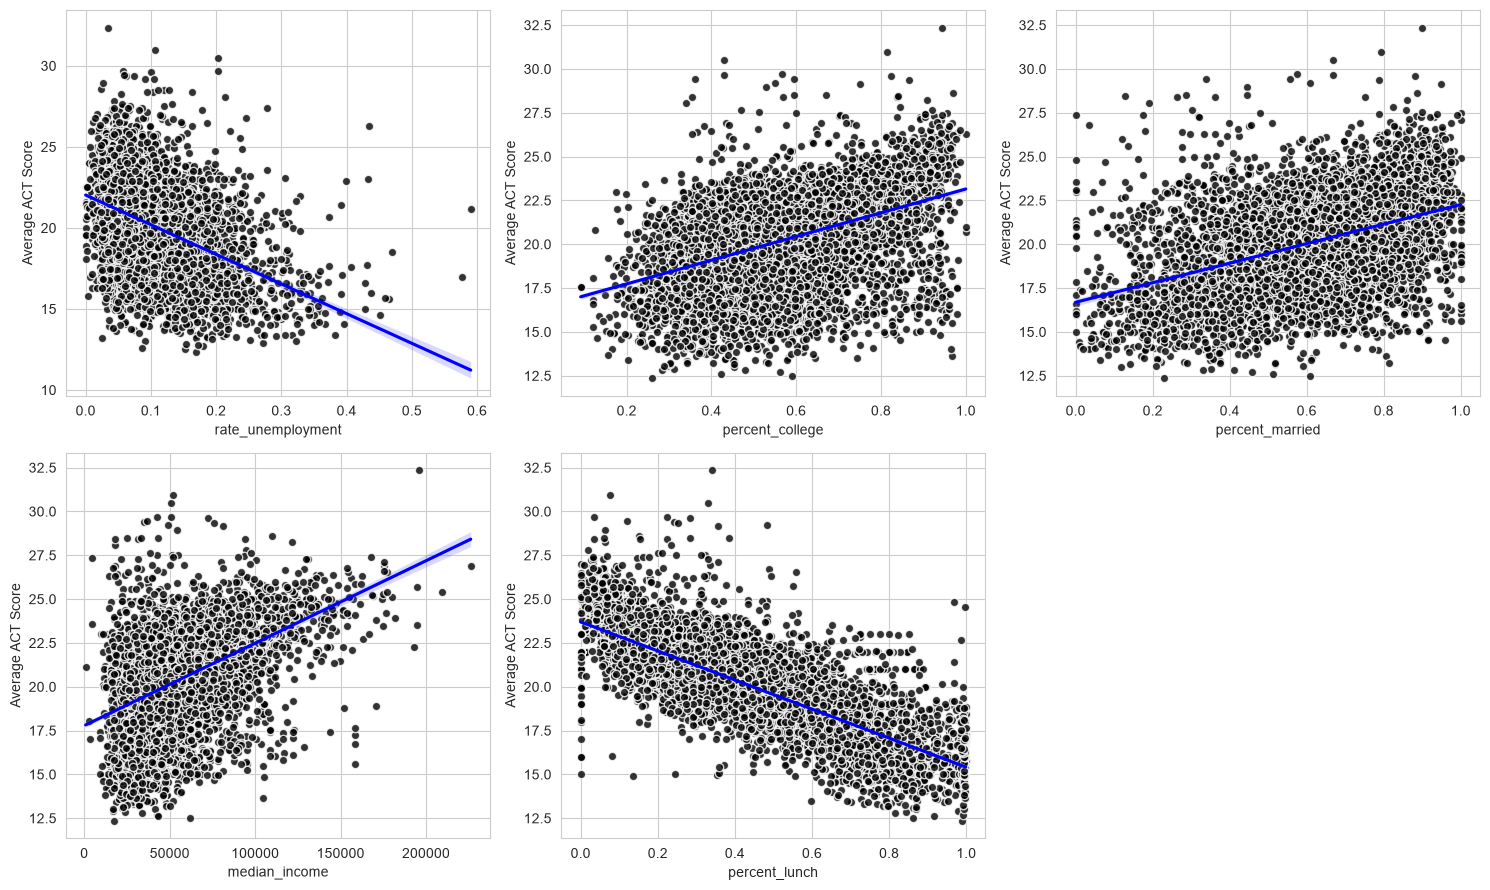

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flat, numerical_predictors):
    sns.regplot(
        data=df,
        x=col,
        y='average_act',
        ax=ax,
        scatter_kws={'color': 'black','edgecolors': 'white', 'linewidths':1},
        line_kws={'color': 'blue'}
    )

    ax.set_xlabel(col)
    ax.set_ylabel('Average ACT Score')

# Remove unused sixth subplot
fig.delaxes(axes.flat[-1])

plt.tight_layout()
plt.show()

* The scatterplots show that all five socioeconomic variables are showing approximately linear relationship with average ACT scores.
* Median household income, percent college, and the percentage of children in married families are positively associated with ACT scores,
* While unemployment and percent lunch show negative associations.


## Correlation

In [25]:
act_corr = (
    df[numerical_predictors + ['average_act']]
    .corr()
    ['average_act']
    .drop('average_act')
    .sort_values(ascending=False)
)

act_corr

median_income        0.450701
percent_college      0.445110
percent_married      0.430010
rate_unemployment   -0.420050
percent_lunch       -0.778008
Name: average_act, dtype: float64

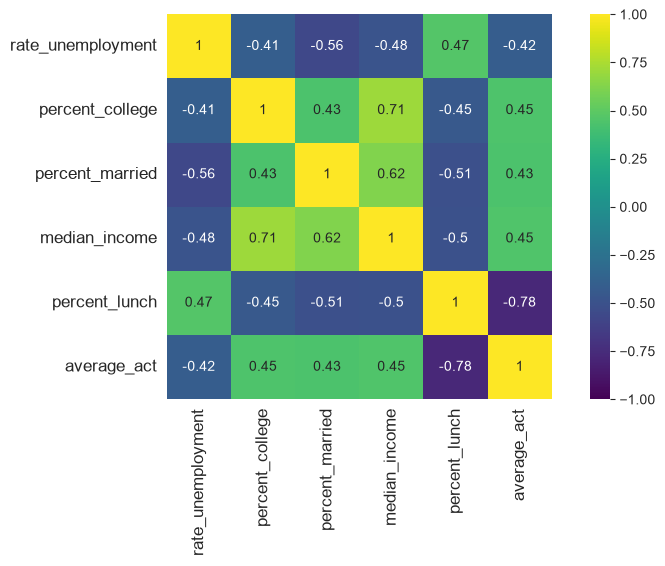

In [26]:
corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

* Correlation analysis was conducted to examine linear relationships between average ACT scores and or socioeconomic predictors.
* The percentage of students receiving lunch had the strongest association with ACT scores with correlation of -.78.
* Median household income, percent married and percent college each showed positive correlations
* Unemployment rate also showed moderate negative correlation.
* Additionally, We need to consider potintial correlation between predictors. For example, the correlation matrix also revealed relationships between median household income and percent college 

### Socioeconomic conditions by charter status

In [27]:
df[df['charter'].isin(['Yes', 'No'])].groupby('charter')[
    numerical_predictors
].mean().round(3)

,rate_unemployment,percent_college,percent_married,median_income,percent_lunch
charter,,,,,
No,0.096,0.572,0.642,52914.904,0.411
Yes,0.132,0.560,0.520,44483.507,0.538


* Charter schools are associated with higher average unemployment rates,
* Charter schools also have lower median household income and greater percent lunch participation.
* The percentage of children living in married-couple families is also lower in charter schools.

## EDA Summary

Exploratory analysis revealed that average ACT scores are approximately normal, with a mean of 20.24 and a median of 20.42.

The distributions of median household income and unemployment rates are right-skewed, with several extreme observations.

Correlation analysis identified lunch participation as having the strongest linear association with average ACT scores. Median household income, college attainment, and the percentage of children in married families showed positive associations, while unemployment rate showed a negative association with school ACT scores.

Additionally, the analysis also reviewed assocation of school average ACT scores between charter and non-charter schools. Charter schools had lower average ACT scores.

These findings motivated the selection of lunch participation for simple linear regression, the inclusion of five socioeconomic predictors in multiple regression, and the investigation of charter-school status as a categorical predictor.